In [ ]:
import pickle
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy
import matplotlib.pyplot as plt
import operator
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

from matplotlib.colors import CenteredNorm

from cmfa.functions import ordered_ilr_func


In [10]:
RESULTS_DIR = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"

In [3]:
true_flux = np.load(RESULTS_DIR / "true_flux.npy", allow_pickle=True).item()
true_id = np.load(RESULTS_DIR / "true_composition.npy", allow_pickle=True).item()
print(f"True flux: {true_flux}")
print(f"True isotopologue distribution: {true_id}")

True flux: {'v8': Array(0.215, dtype=float64), 'v1': Array(1., dtype=float64), 'v19': Array(0.05, dtype=float64), 'v20': Array(0.03, dtype=float64), 'v16': Array(0.07, dtype=float64), 'v17': Array(0.23, dtype=float64), 'v18': Array(0.12, dtype=float64), 'v2': Array(0.201, dtype=float64), 'v9': Array(0.296, dtype=float64), 'v3': Array(0.621, dtype=float64), 'v4': Array(0.621, dtype=float64), 'v5': Array(0.621, dtype=float64), 'v6': Array(0.592, dtype=float64), 'v11': Array(1.213, dtype=float64), 'v12': Array(0.296, dtype=float64), 'v13': Array(1.509, dtype=float64), 'v14': Array(1.735, dtype=float64), 'v15': Array(5.561, dtype=float64), 'v10': Array(0.475, dtype=float64), 'v7': Array(0.807, dtype=float64)}
True isotopologue distribution: {'lysx_123456': Array([0.01567147, 0.11709665, 0.24642148, 0.28673379, 0.21348085,
       0.10003428, 0.02056148], dtype=float64), 'valx_12345': Array([0.0128301 , 0.10251097, 0.27570439, 0.34531928, 0.21147698,
       0.05215829], dtype=float64), 'aspx

# Reference 

In [4]:
with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_ref = pickle.load(f)

In [5]:
with open(RESULTS_DIR / "estimated_fluxes_ci_reference.pkl", "rb") as f:
    flux_ci_ref = pickle.load(f)

In [6]:
with open(RESULTS_DIR / "estimated_ids_reference.pkl", "rb") as f:
    estimated_ids_ref = pickle.load(f)

In [7]:
estimated_fluxes_ref["trad"].shape

(100, 3)

In [8]:
true_ref = np.array([true_flux[k] for k in ["v8", "v2", "v9"]])

resid_trad = estimated_fluxes_ref["trad"][:,:] - true_ref[None, :]
resid_clr = estimated_fluxes_ref["clr"][:,:] - true_ref[None, :]
resid_ilr = estimated_fluxes_ref["ilr"][:,:] - true_ref[None, :]

mse_trad = (resid_trad ** 2).mean(axis=(0))
mse_clr = (resid_clr ** 2).mean(axis=(0))
mse_ilr = (resid_ilr ** 2).mean(axis=(0))

mse_trad, mse_clr, mse_ilr

(Array([0.06468856, 0.0001372 , 0.00960742], dtype=float64),
 Array([2.67663218e-02, 5.08752912e-05, 2.41934760e-03], dtype=float64),
 Array([2.68262269e-02, 5.16457907e-05, 2.42502851e-03], dtype=float64))

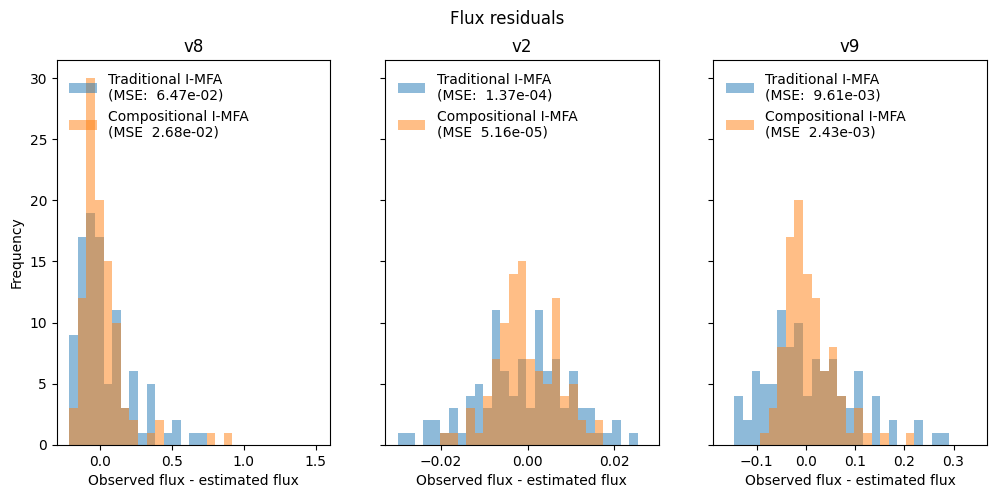

In [9]:
f, axes = plt.subplots(1, 3, figsize=[12, 5], sharey=True)
free_flux_numbers = jnp.array([8,2,9])
for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, i].flatten()
    resid_comp_i = resid_ilr[:, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {mse_trad[i]: .2e})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i]: .2e})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{free_flux_numbers[i]}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");
f.savefig(PLOT_DIR / "flux_residuals_tca.png", bbox_inches="tight", dpi=200)

In [11]:
flux_ci_trad_ref = jnp.exp(jnp.log(flux_ci_ref["trad"][:,:,:]).mean(axis=0))
flux_ci_ilr_ref = jnp.exp(jnp.log(flux_ci_ref["ilr"][:,:,:]).mean(axis=0))

In [12]:
flux = list(true_flux.keys())
print(f"{'Traditional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_trad_ref):
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

               Traditional                
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v8     |          0.0000 |             inf
v1     |          1.0000 |          1.0000
v19    |          0.0500 |          0.0500
v20    |          0.0300 |          0.0300
v16    |          0.0700 |          0.0700
v17    |          0.2300 |          0.2300
v18    |          0.1200 |          0.1200
v2     |          0.0989 |          0.4020
v9     |          0.0133 |          6.3593
v3     |          0.3074 |          1.2492
v4     |          0.3074 |          1.2492
v5     |          0.3074 |          1.2492
v6     |          0.1449 |          2.3942
v11    |          0.1475 |          9.9048
v12    |          0.1461 |          0.5938
v13    |          0.0910 |         24.8345
v14    |          0.0519 |         57.5445
v15    |          0.0002 |     130028.3315
v10    |          0.0334 |          6.8192
v7     |          0.0000 |             inf


In [13]:
print(f"{'Compositional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_ilr_ref):
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

              Compositional               
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v8     |          0.0162 |          2.3024
v1     |          1.0000 |          1.0000
v19    |          0.0500 |          0.0500
v20    |          0.0300 |          0.0300
v16    |          0.0700 |          0.0700
v17    |          0.2300 |          0.2300
v18    |          0.1200 |          0.1200
v2     |          0.1708 |          0.2362
v9     |          0.1620 |          0.5495
v3     |          0.5280 |          0.7302
v4     |          0.5280 |          0.7302
v5     |          0.5280 |          0.7302
v6     |          0.4278 |          0.8183
v11    |          0.7456 |          1.9722
v12    |          0.2516 |          0.3479
v13    |          0.7887 |          2.8852
v14    |          0.7710 |          3.9010
v15    |          0.3888 |         79.3084
v10    |          0.2657 |          0.8626
v7     |          0.0584 |         11.2061


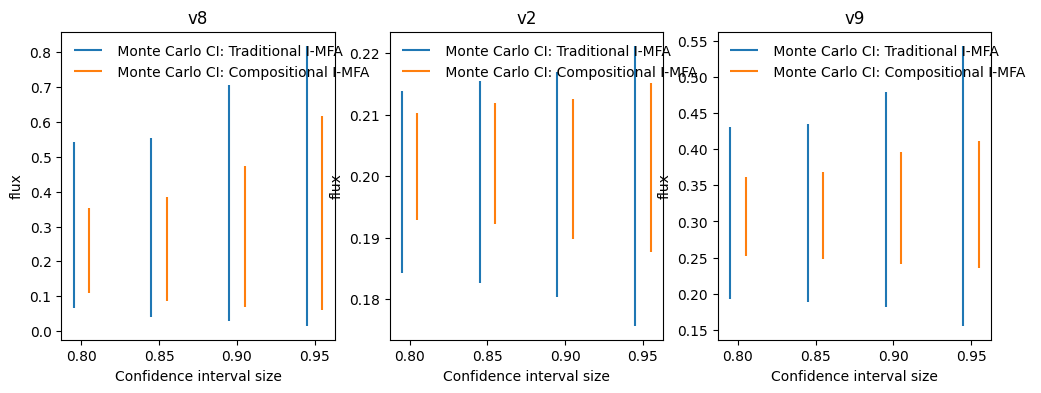

In [14]:
def get_ci_bounds(ci_size):
    low = (1.0 - ci_size) / 2
    high = 1.0 - low
    return low, high


with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    mc_estimated_fluxes = pickle.load(f)

N_BOUND = 4

plot_df_rows = []
ci_sizes = np.linspace(0.80, 0.95, N_BOUND)
for i, ci_size in enumerate(ci_sizes):
    row = {"ci_size": ci_size}
    qlow, qhigh = get_ci_bounds(ci_size)
    for model in ("trad", "ilr"):
        row[f"{model}_low_0"] = np.quantile(mc_estimated_fluxes[model][:, 0], qlow, axis=0)
        row[f"{model}_low_1"] = np.quantile(mc_estimated_fluxes[model][:, 1], qlow, axis=0)
        row[f"{model}_low_2"] = np.quantile(mc_estimated_fluxes[model][:, 2], qlow, axis=0)
        row[f"{model}_high_0"] = np.quantile(mc_estimated_fluxes[model][:, 0], qhigh, axis=0)
        row[f"{model}_high_1"] = np.quantile(mc_estimated_fluxes[model][:, 1], qhigh, axis=0)
        row[f"{model}_high_2"] = np.quantile(mc_estimated_fluxes[model][:, 2], qhigh, axis=0)
    plot_df_rows.append(row)

plot_df = pl.DataFrame(plot_df_rows)
f, axes = plt.subplots(1, 3, figsize=[12, 4])
axes = axes.ravel()
for ax, flux_ix in zip(axes, (0, 1, 2)):
    for offset, model, color in zip((-0.005, 0.005), ("trad", "ilr"), ("tab:blue", "tab:orange")):
        ax.vlines(
            plot_df["ci_size"] + offset, 
            plot_df[f"{model}_low_{flux_ix}"], 
            plot_df[f"{model}_high_{flux_ix}"], 
            color=color,
            label=" Monte Carlo CI: " + model.replace("ilr", "Compositional I-MFA").replace("trad", "Traditional I-MFA")
        )
    # ax.axhline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]: .2f})")
    ax.set(xlabel="Confidence interval size", ylabel="flux", title=f"v{free_flux_numbers[flux_ix]}")
    ax.legend(frameon=False, loc="upper left")

# Sensitivity

In [15]:
free_fluxes = jnp.load(RESULTS_DIR / "free_fluxes.npy", allow_pickle=True)
free_fluxes.shape

(125, 3)

In [16]:
target = np.array([[true_flux['v8'], true_flux['v2'], true_flux['v9']]])
true_flux_index= np.where(np.isclose(free_fluxes,target).all(axis=1))[0].item()
free_fluxes[true_flux_index]

Array([0.215, 0.201, 0.296], dtype=float64)

In [17]:
intensity_msts = jnp.load(RESULTS_DIR / "intensity_measurements.npy", allow_pickle=True)
type(intensity_msts)

list

In [18]:
true_ids = jnp.load(RESULTS_DIR / "true_isotopologue_distributions.npy", allow_pickle=True)
type(true_ids)

list

In [19]:
with open(RESULTS_DIR / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes = pickle.load(f)

In [20]:
with open(RESULTS_DIR / "estimated_ids.pkl", "rb") as f:
    estimated_ids = pickle.load(f)

In [21]:
estimated_fluxes["trad"].shape

(125, 10, 3)

In [22]:
resid_trad = (free_fluxes[:, None, :] - estimated_fluxes["trad"][:, :, :])/free_fluxes[:, None, :]
resid_clr = (free_fluxes[:, None, :] - estimated_fluxes["clr"][:, :, :])/free_fluxes[:, None, :]
resid_ilr = (free_fluxes[:, None, :] - estimated_fluxes["ilr"][:, :, :])/free_fluxes[:, None, :]

mse_trad = (resid_trad ** 2).mean(axis=(0, 1))
mse_clr = (resid_clr ** 2).mean(axis=(0, 1))
mse_ilr = (resid_ilr ** 2).mean(axis=(0, 1))

mse_trad, mse_clr, mse_ilr

(Array([0.8608299 , 0.00425067, 0.08013074], dtype=float64),
 Array([0.31530668, 0.00148539, 0.01982255], dtype=float64),
 Array([0.32394084, 0.00150536, 0.01995289], dtype=float64))

In [23]:
id_resid_trad = [
    [
        {k: true_ids[i][k] - est_val[k] for k in true_ids[0]}
        for est_val in trad_row
    ]
    for i, trad_row in enumerate(estimated_ids["trad"])
]
id_resid_clr = [
    [
        {k: true_ids[i][k] - est_val[k] for k in true_ids[0]}
        for est_val in trad_row
    ]
    for i, trad_row in enumerate(estimated_ids["clr"])
]
id_resid_ilr = [
    [
        {k: true_ids[i][k] - est_val[k] for k in true_ids[0]}
        for est_val in trad_row
    ]
    for i, trad_row in enumerate(estimated_ids["ilr"])
]

n_elements = len(id_resid_trad) * len(id_resid_trad[0])

id_mse_trad = {
    k: sum(row[col][k]**2 for row in id_resid_trad for col in range(len(row))) / n_elements
    for k in true_ids[0]
}
id_mse_clr = {
    k: sum(row[col][k]**2 for row in id_resid_clr for col in range(len(row))) / n_elements
    for k in true_ids[0]
}
id_mse_ilr = {
    k: sum(row[col][k]**2 for row in id_resid_ilr for col in range(len(row))) / n_elements
    for k in true_ids[0]
}


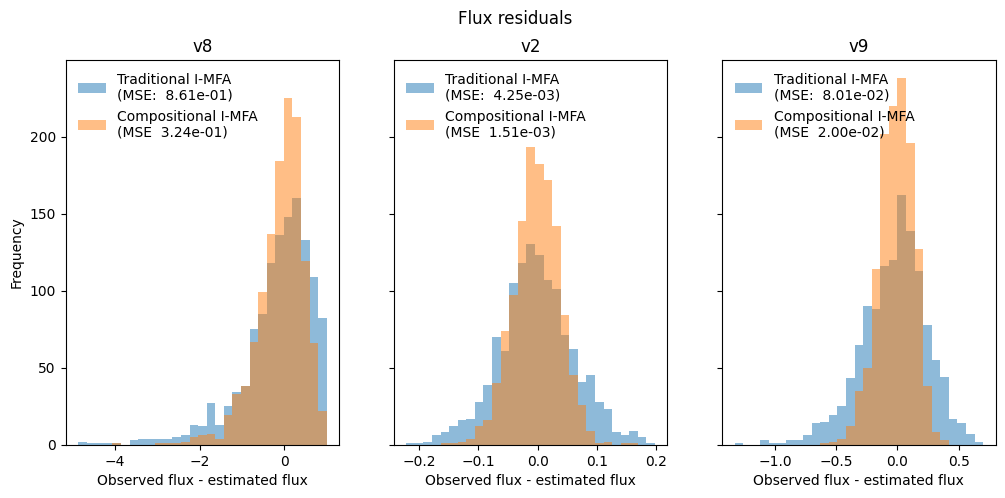

In [24]:
f, axes = plt.subplots(1, 3, figsize=[12, 5], sharey=True)
free_flux_numbers = jnp.array([8,2,9])
for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, :, i].flatten()
    resid_comp_i = resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {mse_trad[i]: .2e})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i]: .2e})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{free_flux_numbers[i]}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");
f.savefig(PLOT_DIR / "flux_residuals_toy.png", bbox_inches="tight", dpi=200)

In [27]:
id_resid_trad_lysx = jnp.array([
    id_resid_trad[i][j]["lysx_123456"] 
    for i in range(len(free_fluxes)) 
    for j in range(10)
])

id_resid_ilr_lysx = jnp.array([
    id_resid_ilr[i][j]["lysx_123456"] 
    for i in range(len(free_fluxes)) 
    for j in range(10)
])

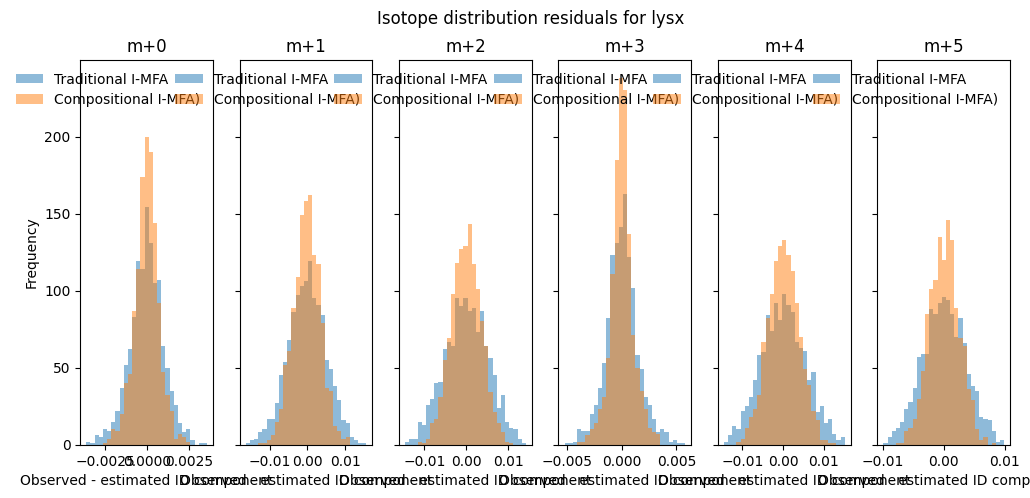

In [28]:
f, axes = plt.subplots(1, 6, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = id_resid_trad_lysx[:, i].flatten()
    resid_comp_i = id_resid_ilr_lysx[:, i].flatten()
    xmin = np.quantile(resid_trad_i, 0.001)
    xmax = np.quantile(resid_trad_i, 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA)" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"m+{i}", xlabel="Observed - estimated ID component")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");

f.suptitle("Isotope distribution residuals for lysx");

In [29]:
with open(RESULTS_DIR / "entropies.npy", "rb") as f:
    entropies = pickle.load(f)
len(entropies)

0

In [30]:
entropies_max = [max(idx.values()) for idx in entropies]
diff_flux = ((resid_trad ** 2).mean(axis=1) - (resid_ilr ** 2).mean(axis=1))
# /(resid_trad ** 2).mean(axis=1)

ValueError: x and y must be the same size

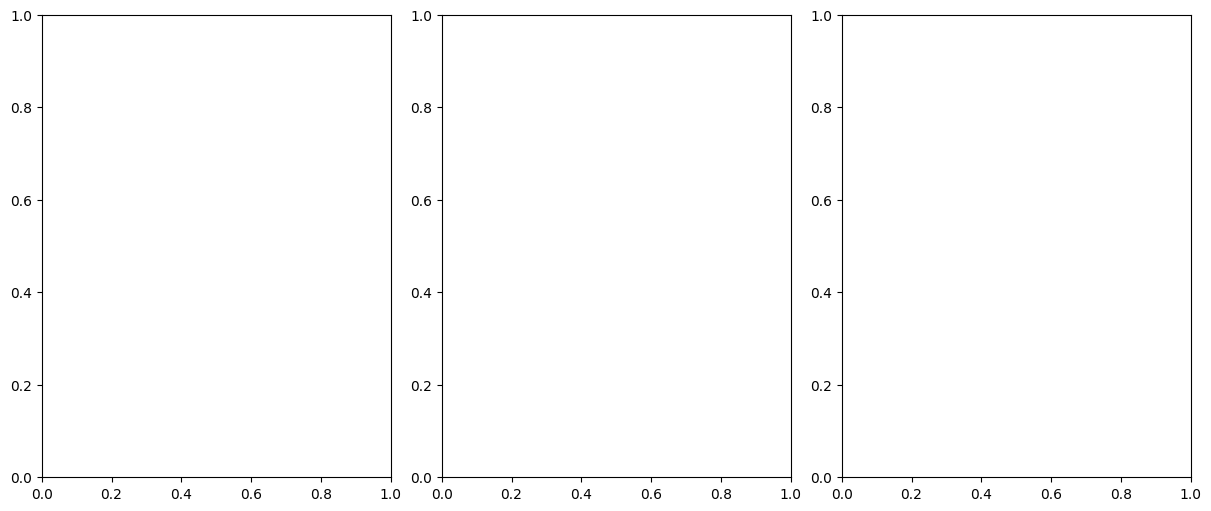

In [31]:
f, axes = plt.subplots(1, 3, figsize=[12, 5], layout= "constrained")
axes = axes.ravel()
point_size=20
for i in range(3):
    y_values = diff_flux[:,i]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes[i].scatter(entropies_max, y_values, c=colors, s=point_size)
    axes[i].scatter(entropies_max[true_flux_index], y_values[true_flux_index], color="black", s=point_size)
    axes[i].axhline(0, color='black', lw=1, alpha=0.5, label="Reference flux")
    axes[i].set(xlabel="Entropy", ylabel="diff", title=f"v{free_flux_numbers[i]}")
f.suptitle("Flux NMSE: traditional - compositional")

plt.show()

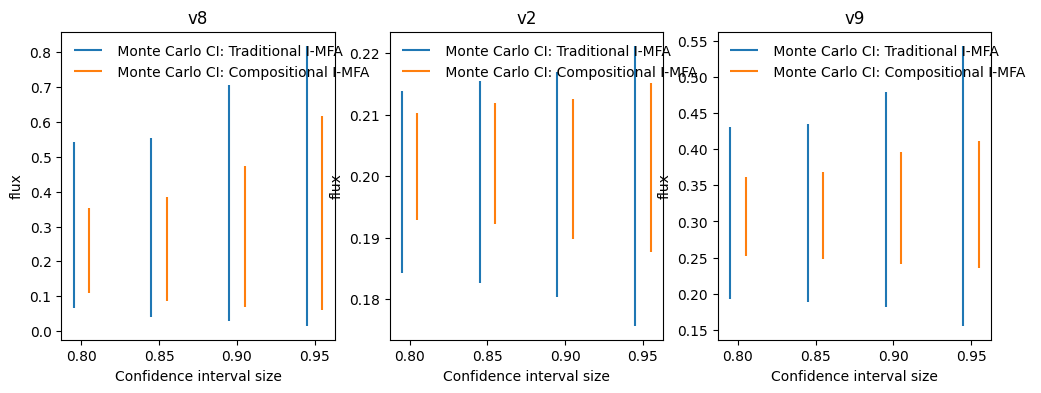

In [32]:
def get_ci_bounds(ci_size):
    low = (1.0 - ci_size) / 2
    high = 1.0 - low
    return low, high


with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    mc_estimated_fluxes = pickle.load(f)

N_BOUND = 4

plot_df_rows = []
ci_sizes = np.linspace(0.80, 0.95, N_BOUND)
for i, ci_size in enumerate(ci_sizes):
    row = {"ci_size": ci_size}
    qlow, qhigh = get_ci_bounds(ci_size)
    for model in ("trad", "ilr"):
        row[f"{model}_low_0"] = np.quantile(mc_estimated_fluxes[model][:, 0], qlow, axis=0)
        row[f"{model}_low_1"] = np.quantile(mc_estimated_fluxes[model][:, 1], qlow, axis=0)
        row[f"{model}_low_2"] = np.quantile(mc_estimated_fluxes[model][:, 2], qlow, axis=0)
        row[f"{model}_high_0"] = np.quantile(mc_estimated_fluxes[model][:, 0], qhigh, axis=0)
        row[f"{model}_high_1"] = np.quantile(mc_estimated_fluxes[model][:, 1], qhigh, axis=0)
        row[f"{model}_high_2"] = np.quantile(mc_estimated_fluxes[model][:, 2], qhigh, axis=0)
    plot_df_rows.append(row)


plot_df = pl.DataFrame(plot_df_rows)
f, axes = plt.subplots(1, 3, figsize=[12, 4])
axes = axes.ravel()
for ax, flux_ix in zip(axes, (0, 1, 2)):
    for offset, model, color in zip((-0.005, 0.005), ("trad", "ilr"), ("tab:blue", "tab:orange")):
        ax.vlines(
            plot_df["ci_size"] + offset, 
            plot_df[f"{model}_low_{flux_ix}"], 
            plot_df[f"{model}_high_{flux_ix}"], 
            color=color,
            label=" Monte Carlo CI: " + model.replace("ilr", "Compositional I-MFA").replace("trad", "Traditional I-MFA")
        )
    # ax.axhline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]: .2f})")
    ax.set(xlabel="Confidence interval size", ylabel="flux", title=f"v{free_flux_numbers[flux_ix]}")
    ax.legend(frameon=False, loc="upper left")

In [ ]:
import numpy as np
import jax
import jax.numpy as jnp
from functools import partial
import pypesto
import optimistix
from pypesto.result import OptimizerResult
import pypesto.profile as profile
import sys

# Ensure your custom module is findable
sys.path.insert(0, "../scripts")
import tca_cycle

# 1. Setup Data
sd_tree = {'aspx_1234': np.array([0.00563536, 0.02463775, 0.02397602, 0.02192304, 0.0092158]), 'lysx_123456': np.array([0.00171235, 0.01146438, 0.02068939, 0.0228282 , 0.01903322,
       0.01008254, 0.00221935]), 'suc_1234': np.array([0.00804308, 0.02793087, 0.02349203, 0.01709231, 0.00575684]), 'valx_12345': np.array([0.00142505, 0.01042039, 0.02275473, 0.02572722, 0.01935234,
       0.00560672])}

# sim_id = np.array([7.53277594e-05, 8.48833378e-01, 1.50278066e-01, 8.13228693e-04])
mst_j = {'aspx_1234': np.array([0.04919876, 0.28953311, 0.33867036, 0.23994568, 0.0826521]), 'lysx_123456': np.array([0.01689806, 0.13478181, 0.25255108, 0.27031265, 0.21235741,
       0.09213284, 0.02096614]), 'suc_1234': np.array([0.09583063, 0.36073381, 0.31398206, 0.17592109, 0.0535324]), 'valx_12345': np.array([0.01544494, 0.09923165, 0.26965416, 0.3501396 , 0.20867884,
       0.05685081])}

# 2. Optimization with Optimistix
# Note: Ensure loss_trad signature is: loss_trad(params, args)
# INITIAL_GUESS = {'v8': 0.2, 'v2': 0.2, 'v9': 0.2}
# init_guess = np.array([0.2, 0.2, 0.2])
# solver = optimistix.BFGS(rtol=1e-8, atol=1e-8)

# opt_result = optimistix.minimise(
#     tca_cycle.loss_trad,
#     y0=jnp.log(init_guess),
#     args=(mst_j, jax.tree.map(lambda s: 1/s, sd_tree)),
#     solver=solver,
#     max_steps=10000,
#     throw=False,
#     has_aux=True,
# )


In [ ]:
import numpy as np
import jax
import jax.numpy as jnp
from functools import partial
import pypesto
import optimistix
from pypesto.result import OptimizerResult
import pypesto.profile as profile
import sys

# Ensure your custom module is findable
sys.path.insert(0, "../scripts")
import tca_cycle



# 3. Create pyPESTO Objective
# PyPESTO will call this function as objective(x)
def my_loss_function(x): 
    return tca_cycle.loss_trad(x, args=(mst_j, jax.tree.map(lambda s: 1/s, sd_tree)))[0] 

objective = pypesto.Objective(fun=my_loss_function)

# 4. Define Problem
problem = pypesto.Problem(
    objective=objective,
    lb=[-5] * 3, 
    ub=[5] * 3,  
    x_names=['v8', 'v2', "v9"]
)

# 5. Manually inject the Optimistix result into pyPESTO
result = pypesto.Result(problem=problem)
opt_result_manual = OptimizerResult(
    x=opt_result.value,        # Convert JAX to NumPy
    fval=float(opt_result.state.f_info.f),          # Cast JAX scalar to float
    id="optimistix_bfgs",
)
result.optimize_result.append(opt_result_manual)

# 6. Profile Likelihood
# pyPESTO will now use Scipy to "walk" the likelihood surface
result = profile.parameter_profile(
    problem=problem,
    result=result,
    optimizer=pypesto.optimize.ScipyOptimizer(),
    filename=None
)

  0%|          | 0/6 [00:00<?, ?it/s]

100%|██████████| 6/6 [09:33<00:00, 95.52s/it] 


[<Axes: xlabel='v8', ylabel='Log-posterior ratio'>,
 <Axes: xlabel='v2'>,
 <Axes: xlabel='v9', ylabel='Log-posterior ratio'>]

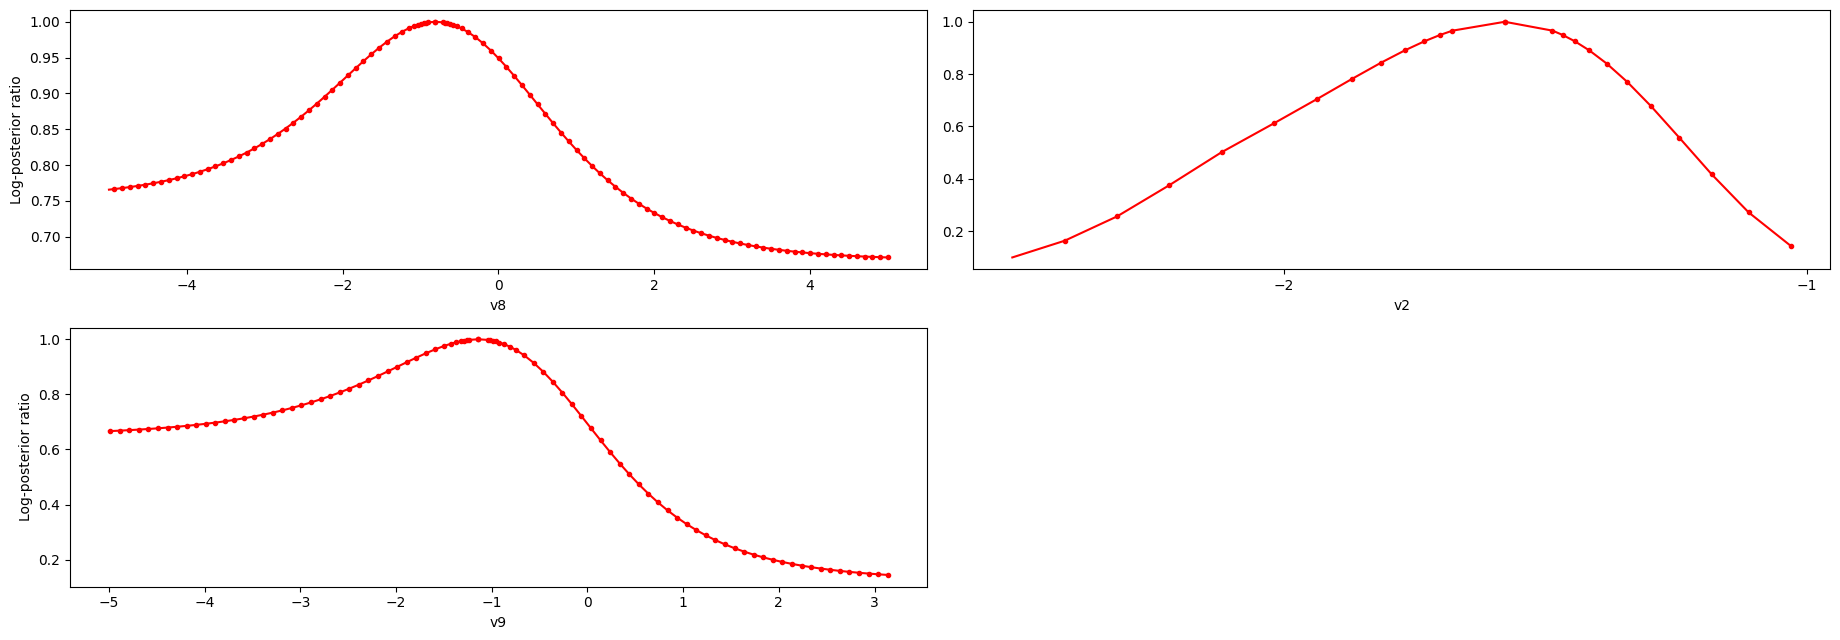

In [42]:
pypesto.visualize.profiles(result)

In [43]:
result.profile_result.get_profiler_result(0)["x_path"][0] = np.exp(result.profile_result.get_profiler_result(0)["x_path"][0])
result.profile_result.get_profiler_result(1)["x_path"][1] = np.exp(result.profile_result.get_profiler_result(1)["x_path"][1])
result.profile_result.get_profiler_result(2)["x_path"][2] = np.exp(result.profile_result.get_profiler_result(2)["x_path"][2])

[<Axes: xlabel='v8', ylabel='Log-posterior ratio'>,
 <Axes: xlabel='v2'>,
 <Axes: xlabel='v9', ylabel='Log-posterior ratio'>]

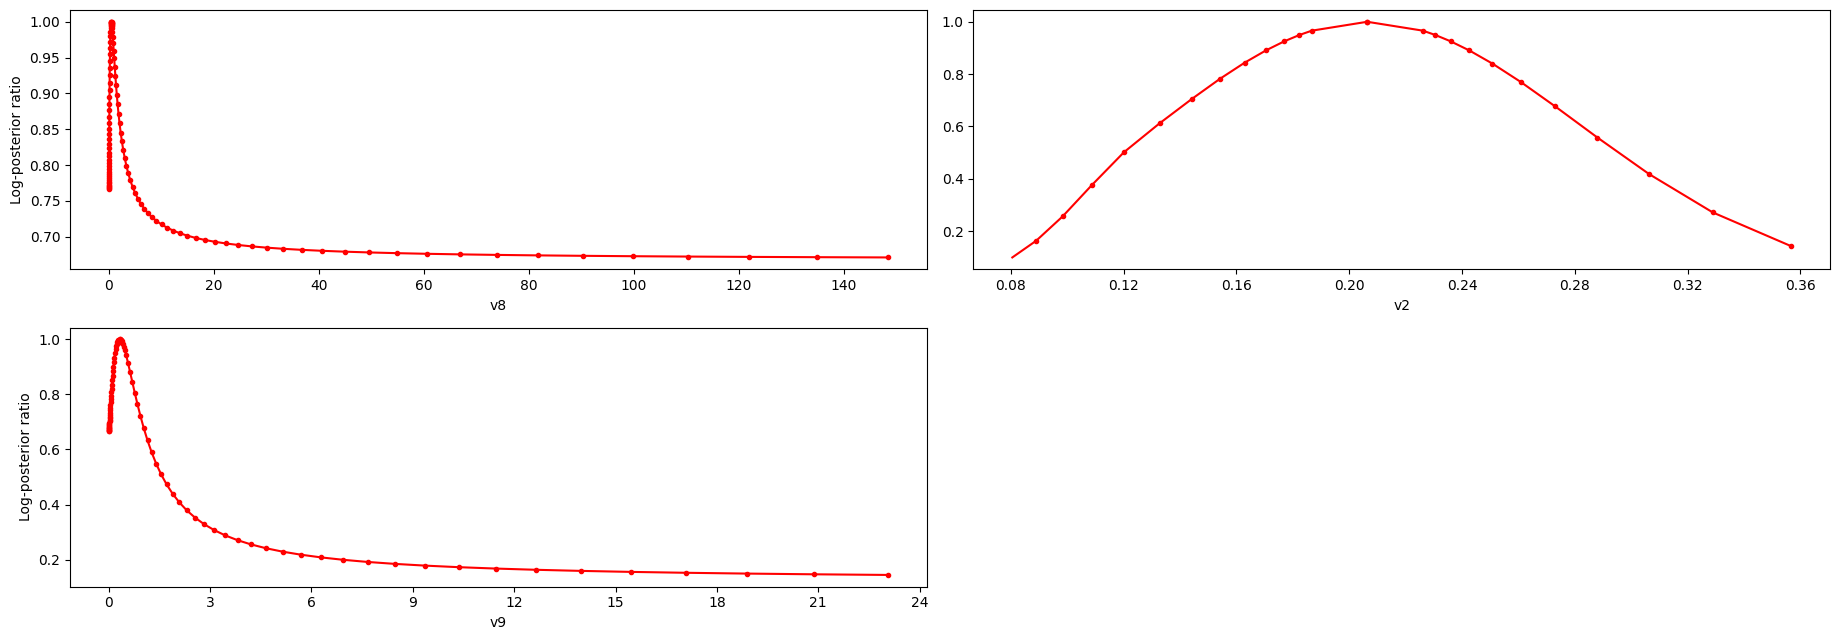

In [44]:
pypesto.visualize.profiles(result)

In [11]:
import scipy.stats as stats

In [24]:
simulated_mid = jnp.load(RESULTS_DIR / "id_simulated_reference.npy", allow_pickle=True).item()

with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_ref = pickle.load(f)

with open(RESULTS_DIR / "estimated_fluxes_sd_reference.pkl", "rb") as f:
    estimated_fluxes_sd = pickle.load(f)

with open(RESULTS_DIR / "fvalues_reference.pkl", "rb") as f:
    fvals = pickle.load(f)

s1 = 235
s2 = 255
s3 = 919

sim_mid = jax.tree.map(lambda x: x[s1], simulated_mid)
mid_sd_trad = jax.tree.map(lambda x: np.std(x, axis=0), simulated_mid)
mid_sd_ilr = jax.tree.map(lambda x: np.std(ordered_ilr_func(x), axis=0), simulated_mid)


flux_est_trad = estimated_fluxes_ref["trad"][s1, :]
flux_est_ilr = estimated_fluxes_ref["ilr"][s1, :]

flux_sd_trad = estimated_fluxes_sd["trad"][s1, [0,7,8]]
flux_sd_ilr = estimated_fluxes_sd["ilr"][s1, [0,7,8]]

fval_trad = fvals["trad"][s1]
fval_ilr = fvals["ilr"][s1]

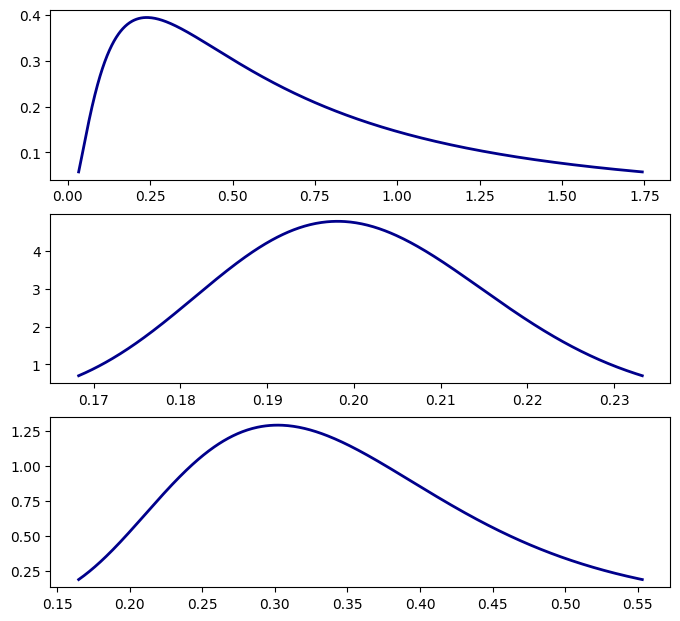

In [26]:
num_fluxes = 3
params = flux_est_ilr
standard_errors = flux_sd_ilr
fig, axes = plt.subplots(num_fluxes, 1, figsize=(8, 2.5 * num_fluxes), sharex=False)
for i in range(num_fluxes):
        ax = axes[i]
        mu = np.log(params[i])
        sigma = standard_errors[i]
        
        # Generate an X-axis evaluation range wide enough to capture the curve
        x_start = (mu - 1.96 * sigma)
        x_end = (mu + 1.96 * sigma)
        x_axis = np.linspace(x_start, x_end, 500)
        
        # Calculate Log-Normal PDF
        y_raw = stats.norm.pdf(x_axis, mu, sigma)
        y_scaled = y_raw / np.max(y_raw)
        
        # Plot the continuous curve
        ax.plot(np.exp(x_axis), y_raw, label='Probability Density', color='darkblue', lw=2)



In [27]:
def fisher_interval(flux_est, flux_sd):
    mu = np.log(flux_est)
    sigma = flux_sd
    x_start = (mu - 1.96 * sigma)
    x_end = (mu + 1.96 * sigma)
    x_axis = np.linspace(x_start, x_end, 500)
    
    # Calculate Log-Normal PDF
    y_raw = stats.norm.pdf(x_axis, mu, sigma)
    y_scaled = y_raw / np.max(y_raw)

    return np.exp(x_axis), y_scaled


In [32]:
x_ilr, y_ilr = fisher_interval(flux_est_ilr[0], flux_sd_ilr[0])

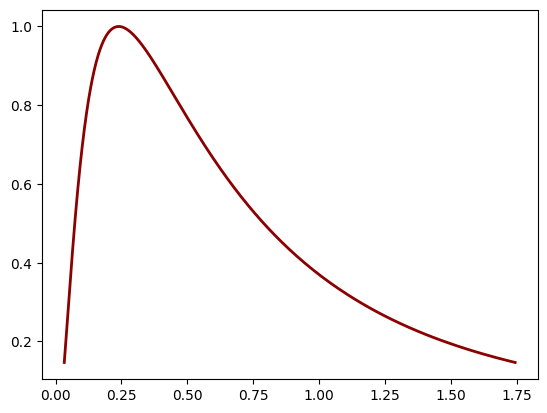

In [33]:
plt.plot(x_ilr, y_ilr, label='Fisher information', color='darkred', lw=2)